<a href="https://colab.research.google.com/github/littlebit0/2026.LA/blob/main/%EC%8B%A4%EC%8A%B52.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

INF = 1000 # 그림판 크기
LEN = 100 # 처음 사각형의 크기

In [32]:
def draw_axis(ax):
  ax.axhline(0, color='black', alpha=0.3) #x-axis line
  ax.axhline(0, color='black', alpha=0.3) #y-axis line
  ax.set_xlim(-INF,INF)
  ax.set_ylim(-INF,INF)
  ax.set_aspect('equal') # 정사각형 모양으로 backboard 그리기

In [33]:
def draw_object(ax):
  p1 = np.array([0,0])
  p2 = np.array([LEN,0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0,LEN])

  # 기본 사각형 그리기
  draw_rectangle(ax,p1,p2,p3,p4)

  # 중앙 조종석(변환된 사각형) 추가로 그리기
  draw_cockpit(ax,p1,p2,p3,p4)

  # 왼쪽 날개축 그리기
  draw_left_arm(ax,p1,p2,p3,p4)

  # 왼쪽 날개 그리기
  draw_left_wing(ax,p1,p2,p3,p4)

  # 오른쪽 날개축 그리기
  draw_right_arm(ax,p1,p2,p3,p4)

  # 오른쪽 날개 그리기
  draw_right_wing(ax,p1,p2,p3,p4)

In [34]:
def draw_rectangle(ax,p1,p2,p3,p4):
  my_polygon = Polygon([p1,p2,p3,p4])
  ax.add_patch(my_polygon)

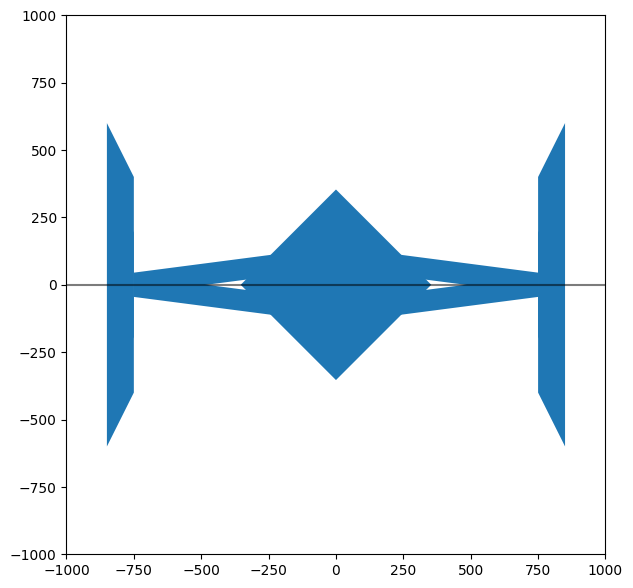

In [35]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()

In [36]:
# 점 p를 x축 방향으로 dx만큼 y축 방향으로 dy만큼 이동시킨 점 q 좌표 구하기
# q = T(dx, dy) p1

def translate(p, dx, dy):
  # 1. 동차좌표계로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 이동 변환 행렬 생성
  m = np.array([[1.0, 0.0, dx], [0.0, 1.0, dy], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m,hp) # (3,3)*(3,1) => (3,1)
  # print(q)

  # 4. 2차원 좌표계로 변환ㄴ
  q = np.array([q[0], q[1]])
  return q

In [37]:
def rotate(p, theta):
    # 점 p를 원점 기준 반시계 방향으로 theta(라디안)만큼 회전시킨 점 q를 구할 것
    # q = R(theta) p
    # 1. 동차좌표계 (homogeneous coordinate)으로 변환
    hp = np.array([p[0], p[1], 1.0])
    # 2. 회전 변환 행렬 생성
    m = np.array([[np.cos(theta), -np.sin(theta), 0.0],
                  [np.sin(theta),  np.cos(theta), 0.0],
                  [0.0, 0.0, 1.0]])
    # 3. 행렬과 벡터의 곱
    q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
    # 4. 2차원 좌표계로 변환
    q = np.array([q[0], q[1]])
    return q

In [38]:
def scale(p, sx, sy):
    # 점 p를 x축 방향으로 sx배, y축 방향으로 sy배 크기 변환한 점 q를 구할 것
    # q = S(sx, sy) p
    # 1. 동차좌표계 (homogeneous coordinate)으로 변환
    hp = np.array([p[0], p[1], 1.0])
    # 2. 크기 변환 행렬 생성
    m = np.array([[sx, 0.0, 0.0],
                  [0.0, sy, 0.0],
                  [0.0, 0.0, 1.0]])
    # 3. 행렬과 벡터의 곱
    q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
    # 4. 2차원 좌표계로 변환
    q = np.array([q[0], q[1]])
    return q

In [39]:
def shear_x(p, sx):
    # 점 p를 x축 방향으로 기울인(밀어낸) 점 q를 구할 것: q.x = p.x + sx * p.y, q.y = p.y
    # q = Shx(sx) p
    # 1. 동차좌표계 (homogeneous coordinate)으로 변환
    hp = np.array([p[0], p[1], 1.0])
    # 2. x축 기울기 변환 행렬 생성
    m = np.array([[1.0, sx, 0.0],
                  [0.0, 1.0, 0.0],
                  [0.0, 0.0, 1.0]])
    # 3. 행렬과 벡터의 곱
    q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
    # 4. 2차원 좌표계로 변환
    q = np.array([q[0], q[1]])
    return q

In [40]:
def shear_y(p, sy):
    # 점 p를 y축 방향으로 기울인(밀어낸) 점 q를 구할 것: q.x = p.x, q.y = sy * p.x + p.y
    # q = Shy(sy) p
    # 1. 동차좌표계 (homogeneous coordinate)으로 변환
    hp = np.array([p[0], p[1], 1.0])
    # 2. y축 기울기 변환 행렬 생성
    m = np.array([[1.0, 0.0, 0.0],
                  [sy, 1.0, 0.0],
                  [0.0, 0.0, 1.0]])
    # 3. 행렬과 벡터의 곱
    q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
    # 4. 2차원 좌표계로 변환
    q = np.array([q[0], q[1]])
    return q

In [41]:
def reflect_x(p):
    # 점 p를 x축에 대해 반전시킨 점 q를 구할 것: q.x = p.x, q.y = -p.y
    # q = Rfx p
    # 1. 동차좌표계 (homogeneous coordinate)으로 변환
    hp = np.array([p[0], p[1], 1.0])
    # 2. x축 반전 변환 행렬 생성
    m = np.array([[1.0, 0.0, 0.0],
                  [0.0, -1.0, 0.0],
                  [0.0, 0.0, 1.0]])
    # 3. 행렬과 벡터의 곱
    q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
    # 4. 2차원 좌표계로 변환
    q = np.array([q[0], q[1]])
    return q

In [42]:
def draw_cockpit(ax,p1,p2,p3,p4): # 중앙 조종석
  # (q1, q2, q3, q4) <- (p1, p2, p3, p4)

  # 1. 사각형을 원점으로 이동변환 : T(-LEN/2, -LEN/2)
  # q = T(-LEN/2, -LEN/2)p
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)

  # 2. 크기 변환 : S(5,5)
  s = 5
  q1 = scale(q1, s, s)
  q2 = scale(q2, s, s)
  q3 = scale(q3, s, s)
  q4 = scale(q4, s, s)

  # 3. 회전 변환 : R(pi/4)
  q1 = rotate(q1, np.pi/4.0)
  q2 = rotate(q2, np.pi/4.0)
  q3 = rotate(q3, np.pi/4.0)
  q4 = rotate(q4, np.pi/4.0)

  draw_rectangle(ax,q1,q2,q3,q4)

In [43]:

# 추가 반전 변환 (기존 reflect_x와 같은 방식)
def reflect_y(p):
  # 점 p를 y축에 대해 반전: q.x = -p.x, q.y = p.y
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[-1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]])
  q = np.dot(m, hp)
  return np.array([q[0], q[1]])

def reflect_origin(p):
  # 점 p를 원점에 대해 반전: q = -p
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[-1.0, 0.0, 0.0], [0.0, -1.0, 0.0], [0.0, 0.0, 1.0]])
  q = np.dot(m, hp)
  return np.array([q[0], q[1]])

def reflect_yx(p):
  # 점 p를 직선 y=x에 대해 반전: q.x = p.y, q.y = p.x
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[0.0, 1.0, 0.0], [1.0, 0.0, 0.0], [0.0, 0.0, 1.0]])
  q = np.dot(m, hp)
  return np.array([q[0], q[1]])

def draw_left_arm(ax,p1,p2,p3,p4): # 왼쪽 날개축
  # 위쪽 팔: 사각형 -> S(5.2, 0.8) -> Shy(0.13) -> T(-750, -35)
  # 아래쪽 팔: 위쪽 팔을 x축 기준 반전(reflect_x)
  ps = [p1, p2, p3, p4]
  up, down = [], []
  for p in ps:
    q = scale(p, 5.2, 0.8)
    q = shear_y(q, 0.13)
    q = translate(q, -750, -35)
    up.append(q)
    down.append(reflect_x(q))
  draw_rectangle(ax, up[0], up[1], up[2], up[3])
  draw_rectangle(ax, down[0], down[1], down[2], down[3])

def draw_left_wing(ax,p1,p2,p3,p4): # 왼쪽 날개
  # 위쪽 조각: 사각형 -> S(1, 6) -> Shy(-2) -> T(-850, 0)
  # 아래쪽 조각: 위쪽 조각을 x축 기준 반전(reflect_x)
  ps = [p1, p2, p3, p4]
  up, down = [], []
  for p in ps:
    q = scale(p, 1.0, 6.0)
    q = shear_y(q, -2.0)
    q = translate(q, -850, 0)
    up.append(q)
    down.append(reflect_x(q))
  draw_rectangle(ax, up[0], up[1], up[2], up[3])
  draw_rectangle(ax, down[0], down[1], down[2], down[3])

def draw_right_arm(ax,p1,p2,p3,p4): # 오른쪽 날개축: 왼쪽 날개축을 y축 기준 반전
  ps = [p1, p2, p3, p4]
  for sign in (1, -1):
    pts = []
    for p in ps:
      q = scale(p, 5.2, 0.8)
      q = shear_y(q, 0.13)
      q = translate(q, -750, -35)
      if sign == -1:
        q = reflect_x(q)
      pts.append(reflect_y(q))
    draw_rectangle(ax, pts[0], pts[1], pts[2], pts[3])

def draw_right_wing(ax,p1,p2,p3,p4): # 오른쪽 날개: 왼쪽 날개를 y축 기준 반전
  ps = [p1, p2, p3, p4]
  for sign in (1, -1):
    pts = []
    for p in ps:
      q = scale(p, 1.0, 6.0)
      q = shear_y(q, -2.0)
      q = translate(q, -850, 0)
      if sign == -1:
        q = reflect_x(q)
      pts.append(reflect_y(q))
    draw_rectangle(ax, pts[0], pts[1], pts[2], pts[3])
